# Round 1 portfolio analysis

**Question:** how did we turn monthly ETF data into a constrained allocation, compare it with simpler rules, and translate it into whole-share positions?

Read from top to bottom. Each calculation is shown here; this notebook does not call separate project scripts. **Restart the kernel and Run All** to reproduce the analysis. The data files are directly in `Data/`, and the final tables and plots are saved in `Results/`.

We use Bloomberg ETF data and an independent FRED risk-free proxy. The main backtest is a **retrospective comparison**, not an untouched holdout. Constraint sensitivity and earlier historical-fit checks are in `supplementary_studies.ipynb`.

## 1. Settings and policy choices

The challenge capital is USD 100 million and the volatility band is 7–9%; we target 8%. The additional floors and concentration caps below are **chosen safeguards**, not mathematically optimal values. They must be distinguished from weights calculated by the optimizer.

The five building blocks are US equity (SPY + SCHD), emerging-market equity (VWO + EEMV), commodities (DBC), short nominal Treasuries (VGSH) and short TIPS (STIP). A 5% building-block floor does **not** require every ETF to hold 5%. XLE is excluded from this universe.

In [1]:
from pathlib import Path
from itertools import product
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import norm
from openpyxl import load_workbook
from IPython.display import display, Markdown

# Open this notebook from the round-1 folder; all input paths are relative to it.
ROOT = Path.cwd()
DATA = ROOT / "Data"
RESULTS = ROOT / "Results"
STUDIES = ROOT / "Studies"
RESULTS.mkdir(exist_ok=True)
STUDIES.mkdir(exist_ok=True)

CAPITAL = 100_000_000
TARGET_VOLATILITY = 0.08
TRADING_COST = 0.001
ASSETS = ["SPY", "VWO", "EEMV", "DBC", "SCHD", "VGSH", "STIP"]
FIT_START = "2021-10"
FIT_END = "2026-09"
BACKTEST_START = "2016-11"
POLICY = {
    "risk_cap": 0.40,
    "capital_cap": 0.35,
    "equity_risk_cap": 0.65,
    "building_block_floor": 0.05,
    "bond_floor": 0.20,
}
GROUPS = {
    "US": ["SPY", "SCHD"],
    "EM": ["VWO", "EEMV"],
    "commodities": ["DBC"],
    "VGSH": ["VGSH"],
    "STIP": ["STIP"],
}
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

In [2]:
policy_description = pd.DataFrame([
    ["ETF capital cap", POLICY["capital_cap"], "Limit capital concentration"],
    ["ETF risk-share cap", POLICY["risk_cap"], "Limit estimated risk concentration"],
    ["Combined equity-risk cap", POLICY["equity_risk_cap"], "Limit dependence on equity risk"],
    ["Each building-block minimum", POLICY["building_block_floor"], "Retain meaningful exposure"],
    ["Combined VGSH + STIP minimum", POLICY["bond_floor"], "Retain a bond allocation"],
], columns=["Rule", "Limit", "Reason"])
display(policy_description.style.format({"Limit": "{:.0%}"}))

,Rule,Limit,Reason
0,ETF capital cap,35%,Limit capital concentration
1,ETF risk-share cap,40%,Limit estimated risk concentration
2,Combined equity-risk cap,65%,Limit dependence on equity risk
3,Each building-block minimum,5%,Retain meaningful exposure
4,Combined VGSH + STIP minimum,20%,Retain a bond allocation


## 2. Prices, returns and estimation inputs

`Data/bloomberg_prices.xlsx` is the original export: one **month-end closing observation**, not a monthly average, per ETF from October 2011 to September 2026. SPY's saved Bloomberg request confirms dividend and split adjustments. Other columns contain saved values; their original adjustment settings are not preserved.

The first date cell contains a saved `#NAME?` error. We use **31 October 2011**, explicitly confirmed by Kyla. The workbook itself is not changed.

Monthly simple return:
$$r_{i,t}=\frac{P_{i,t}}{P_{i,t-1}}-1.$$
For the latest 60 completed months, October 2021–September 2026:
$$\hat\mu_i=12\,\overline r_i,\qquad \hat\Sigma=12\,\operatorname{Cov}(r),\qquad
\hat\sigma_i=\sqrt{12}\,s_i.$$
These means are historical estimates, not guaranteed future returns. Sample standard deviations and covariances use $n-1$ in the denominator. Annualization follows the conventional square-root-of-time approximation.

In [3]:
source_file = DATA / "bloomberg_prices.xlsx"
workbook = load_workbook(source_file, read_only=True, data_only=True)
rows = list(workbook.worksheets[0].values)
workbook.close()
assert list(rows[0][1:8]) == [ticker + " US Equity" for ticker in ASSETS]

source_dates = [row[0] for row in rows[1:]]
# The first cell's saved value is #NAME?; 31 October 2011 was confirmed by Kyla.
if source_dates[0] == "#NAME?":
    source_dates[0] = pd.Timestamp("2011-10-31")
source_dates = pd.DatetimeIndex(source_dates)
assert list(source_dates.to_period("M")) == list(pd.period_range("2011-10", "2026-09", freq="M"))

prices = pd.DataFrame([row[1:8] for row in rows[1:]], index=source_dates, columns=ASSETS).astype(float)
assert np.isfinite(prices.to_numpy()).all() and (prices > 0).all().all()
# Calendar month-end labels align ETF observations with the risk-free series.
# This changes the labels, not the observed prices, and fills no missing values.
prices.index = prices.index.to_period("M").to_timestamp("M")
prices.index.name = "month"
returns = prices.pct_change(fill_method=None).iloc[1:]
training = returns.loc[FIT_START:FIT_END]
assert len(prices) == 180 and len(returns) == 179 and len(training) == 60
assert returns.notna().all().all()
annual_covariance = training.cov() * 12
annual_mean = training.mean() * 12
annual_inputs = pd.DataFrame({
    "annual_mean_input": annual_mean,
    "annual_volatility": training.std(ddof=1) * np.sqrt(12),
})

In [4]:
display(prices.iloc[[0, -1]])
display(annual_inputs.style.format("{:.2%}"))
display(training.corr().style.format("{:.3f}"))

,SPY,VWO,EEMV,DBC,SCHD,VGSH,STIP
month,,,,,,,
2011-10-31,96.6486,27.0764,36.3758,23.4365,5.2877,47.0305,73.4012
2026-09-30,762.6300,59.3100,74.0500,32.3200,32.5300,57.3775,99.7000


,annual_mean_input,annual_volatility
SPY,14.11%,15.67%
VWO,7.45%,14.74%
EEMV,6.65%,11.95%
DBC,13.71%,17.28%
SCHD,10.19%,15.10%
VGSH,1.83%,2.08%
STIP,2.88%,2.83%


,SPY,VWO,EEMV,DBC,SCHD,VGSH,STIP
SPY,1.000,0.635,0.666,0.119,0.708,0.377,0.565
VWO,0.635,1.000,0.880,0.142,0.529,0.514,0.451
EEMV,0.666,0.880,1.000,0.039,0.516,0.527,0.503
DBC,0.119,0.142,0.039,1.000,0.370,-0.173,0.170
SCHD,0.708,0.529,0.516,0.370,1.000,0.358,0.549
VGSH,0.377,0.514,0.527,-0.173,0.358,1.000,0.760
STIP,0.565,0.451,0.503,0.170,0.549,0.760,1.000


## 3. Portfolio risk and contributions

Capital weight is the proportion invested. **Risk share** measures how much of the estimated portfolio variance is attributed to that position, including covariance with other holdings:
$$\sigma_p=\sqrt{w^\top\Sigma w},\qquad
RC_i=\frac{w_i(\Sigma w)_i}{w^\top\Sigma w}.$$
Risk shares sum to one, but generally differ from capital weights. This portfolio is constrained mean-variance optimization; it does not require equal risk contributions.

In [5]:
def portfolio_volatility(weights, covariance):
    return float(np.sqrt(weights @ covariance @ weights))


def risk_shares(weights, covariance):
    variance = weights @ covariance @ weights
    return weights * (covariance @ weights) / variance


def risk_share_gradient(weights, covariance):
    # Analytic derivatives help SLSQP handle the nonlinear risk-share limits.
    marginal_covariance = covariance @ weights
    variance = weights @ marginal_covariance
    numerator_gradient = np.diag(marginal_covariance) + np.diag(weights) @ covariance
    variance_gradient = 2 * marginal_covariance
    return (numerator_gradient / variance
            - np.outer(weights * marginal_covariance, variance_gradient) / variance**2)


def policy_margins(weights, covariance, assets, policy):
    # Nonnegative margins mean the inequalities are satisfied.
    contributions = risk_shares(weights, covariance)
    equity_mask = np.array([ticker in {"SPY", "VWO", "EEMV", "SCHD"} for ticker in assets])
    margins = {
        "long_only": float(np.min(weights)),
        "capital_cap": float(policy["capital_cap"] - np.max(weights)),
        "risk_cap": float(policy["risk_cap"] - np.max(contributions)),
        "equity_risk_cap": float(policy["equity_risk_cap"] - contributions[equity_mask].sum()),
        "bond_floor": float(sum(weights[i] for i, ticker in enumerate(assets)
                                if ticker in {"VGSH", "STIP"}) - policy["bond_floor"]),
    }
    for group, tickers in GROUPS.items():
        exposure = sum(weights[i] for i, ticker in enumerate(assets) if ticker in tickers)
        floor = policy.get("floor_" + group, policy["building_block_floor"])
        margins[group + "_floor"] = float(exposure - floor)
    return pd.Series(margins)

## 4. Choose all weights jointly

We maximize the estimated annual arithmetic return:
$$\max_w\;w^\top\hat\mu,$$
subject to full investment, nonnegative weights, the chosen policy limits and
$$w^\top\hat\Sigma w=0.08^2.$$
SciPy's SLSQP minimizes the negative objective. We try **100 random starting portfolios for each of two seeds** and accept only successful solutions that pass separate feasibility checks. Multiple starts support numerical stability; they do not prove a global optimum for this nonlinear problem. The derivatives in the following functions improve the solver's numerical operation; they do not change the financial objective.

In [6]:
def optimize_weights(sample, policy, target=TARGET_VOLATILITY,
                     seeds=(12, 91), random_starts=100, warm_starts=()):
    assets = list(sample.columns)
    count = len(assets)
    covariance = sample.cov().to_numpy() * 12
    means = sample.mean().to_numpy() * 12
    equity_mask = np.array([ticker in {"SPY", "VWO", "EEMV", "SCHD"} for ticker in assets], dtype=float)

    constraints = [
        {"type": "eq", "fun": lambda w: w.sum() - 1,
         "jac": lambda w: np.ones(count)},
        {"type": "eq", "fun": lambda w: (w @ covariance @ w) / target**2 - 1,
         "jac": lambda w: 2 * covariance @ w / target**2},
        {"type": "ineq", "fun": lambda w: policy["risk_cap"] - risk_shares(w, covariance),
         "jac": lambda w: -risk_share_gradient(w, covariance)},
        {"type": "ineq", "fun": lambda w: policy["equity_risk_cap"] - equity_mask @ risk_shares(w, covariance),
         "jac": lambda w: -equity_mask @ risk_share_gradient(w, covariance)},
    ]
    for group, tickers in {**GROUPS, "bonds": ["VGSH", "STIP"]}.items():
        mask = np.array([ticker in tickers for ticker in assets], dtype=float)
        floor = (policy["bond_floor"] if group == "bonds"
                 else policy.get("floor_" + group, policy["building_block_floor"]))
        # Capture each group's mask and floor separately in these functions.
        constraints.append({"type": "ineq", "fun": lambda w, m=mask, f=floor: m @ w - f,
                            "jac": lambda w, m=mask: m})

    solutions = []
    diagnostics = []
    for seed in seeds:
        generator = np.random.default_rng(seed)
        starts = list(warm_starts) + list(generator.dirichlet(np.ones(count), random_starts))
        valid = []
        for initial_weights in starts:
            solution = minimize(
                fun=lambda w: -means @ w, x0=initial_weights, jac=lambda w: -means,
                bounds=[(0, policy["capital_cap"])] * count,
                constraints=constraints, method="SLSQP",
                options={"ftol": 1e-11, "maxiter": 500},
            )
            candidate = solution.x
            feasible = (abs(candidate.sum() - 1) < 1e-7
                        and abs(portfolio_volatility(candidate, covariance) - target) < 1e-7
                        and policy_margins(candidate, covariance, assets, policy).min() >= -1e-7)
            if solution.success and feasible:
                valid.append(solution)
        diagnostics.append({"seed": seed, "starts": len(starts), "verified_solutions": len(valid),
                            "best_mean_return": -min(s.fun for s in valid) if valid else np.nan})
        solutions.extend(valid)
    if not solutions:
        raise RuntimeError("No verified feasible allocation found; do not substitute arbitrary weights.")
    best = min(solutions, key=lambda solution: solution.fun)
    return best.x, pd.DataFrame(diagnostics)

### Round only after optimization

Target weights are expressed to 0.01 percentage point. Ordinary rounding can cross an active risk cap. If it does, we inspect adjacent rounded values, require full investment and all inequality limits, and choose the feasible rounding closest to the exact solution. The rounded volatility must remain in the 7–8% interval: just below the 8% equality target is the implementation tolerance, not a new optimization objective.

In [7]:
exact_weights, solver_diagnostics = optimize_weights(training, POLICY)
covariance = annual_covariance.to_numpy()

def acceptable_rounding(weights):
    volatility = portfolio_volatility(weights, covariance)
    return (abs(weights.sum() - 1) < 1e-12
            and 0.07 <= volatility <= TARGET_VOLATILITY + 1e-10
            and policy_margins(weights, covariance, ASSETS, POLICY).min() >= -1e-10)

target_weights = np.round(exact_weights, 4)
target_weights[-1] = 1 - target_weights[:-1].sum()
if not acceptable_rounding(target_weights):
    # Try adjacent 0.01 percentage-point grid values, not a new portfolio search.
    lower_weights = np.floor(exact_weights * 10_000) / 10_000
    feasible_roundings = []
    for increments in product([0, 1], repeat=len(ASSETS)):
        candidate = lower_weights + np.array(increments) / 10_000
        if acceptable_rounding(candidate):
            feasible_roundings.append(candidate)
    if not feasible_roundings:
        raise RuntimeError("No nearby rounded allocation satisfies the policy limits.")
    target_weights = min(feasible_roundings, key=lambda w: np.sum((w - exact_weights)**2))

allocation = pd.DataFrame({
    "exact_weight": exact_weights,
    "target_weight": target_weights,
    "risk_share": risk_shares(target_weights, covariance),
    "target_value_usd": target_weights * CAPITAL,
}, index=ASSETS)
allocation.index.name = "ticker"
display(solver_diagnostics.style.format({"best_mean_return": "{:.4%}"}))
display(allocation.style.format({"exact_weight": "{:.6%}", "target_weight": "{:.2%}",
                                 "risk_share": "{:.2%}", "target_value_usd": "${:,.2f}"}))

,seed,starts,verified_solutions,best_mean_return
0,12,100,97,9.2806%
1,91,100,97,9.2806%


,exact_weight,target_weight,risk_share,target_value_usd
ticker,,,,
SPY,26.083326%,26.08%,40.00%,"$26,080,000.00"
VWO,0.000000%,0.00%,0.00%,$0.00
EEMV,9.654292%,9.66%,8.62%,"$9,660,000.00"
DBC,26.956821%,26.95%,39.99%,"$26,950,000.00"
SCHD,3.276419%,3.28%,4.79%,"$3,280,000.00"
VGSH,5.000000%,5.00%,0.37%,"$5,000,000.00"
STIP,29.029141%,29.03%,6.23%,"$29,030,000.00"


In [8]:
policy_checks = policy_margins(target_weights, covariance, ASSETS, POLICY).to_frame("margin")
policy_checks["passes"] = policy_checks["margin"] >= -1e-10
current_volatility = portfolio_volatility(target_weights, covariance)
current_normal_var = norm.ppf(0.95) * current_volatility / np.sqrt(12)
display(policy_checks)
display(pd.Series({"Weights total": target_weights.sum(),
                   "Estimated annual volatility": current_volatility,
                   "Normal one-month 95% VaR": current_normal_var}).to_frame("value").style.format("{:.4%}"))
print(f"Normal VaR on initial capital: ${CAPITAL * current_normal_var:,.2f}")

,margin,passes
long_only,0.000000,True
capital_cap,0.059700,True
risk_cap,0.000001,True
equity_risk_cap,0.115859,True
bond_floor,0.140300,True
US_floor,0.243600,True
EM_floor,0.046600,True
commodities_floor,0.219500,True
VGSH_floor,0.000000,True
STIP_floor,0.240300,True


,value
Weights total,100.0000%
Estimated annual volatility,7.9996%
Normal one-month 95% VaR,3.7984%


Normal VaR on initial capital: $3,798,447.76


## 5. Equal-weight and risk-parity comparisons

Use the **same selected holdings** to isolate the allocation rule. Equal weight assigns $1/N$ of capital to each. Risk parity solves for weights with $RC_i=1/N$ using the same covariance matrix. Its positive risk-budgeting solution can be found by minimizing
$$\frac12 x^\top\Sigma x-\sum_i b_i\log x_i,\quad b_i=1/N,$$
then normalizing $w=x/\sum x_i$.

These are unrestricted comparator rules: we do not impose MVO's additional policy limits on them or lever them to 8%. The same-six-ETF risk-parity portfolio naturally falls below the 7–9% band. This is not a claim that every risk-parity universe would do so.

In [9]:
held_assets = [ticker for ticker in ["SPY", "VWO", "EEMV", "DBC", "VGSH", "SCHD", "STIP"]
               if allocation.loc[ticker, "target_weight"] > 1e-8]
held_covariance = annual_covariance.loc[held_assets, held_assets].to_numpy()

def equal_risk_weights(covariance):
    # Equal risk budgeting: minimize 0.5 x'Σx - sum(b_i log(x_i)), then normalize x.
    count = len(covariance)
    scaled_covariance = covariance / np.mean(np.diag(covariance))
    budgets = np.ones(count) / count
    solution = minimize(
        lambda x: 0.5 * x @ scaled_covariance @ x - budgets @ np.log(x),
        np.ones(count), jac=lambda x: scaled_covariance @ x - budgets / x,
        bounds=[(1e-10, None)] * count, method="L-BFGS-B",
        options={"ftol": 1e-15, "gtol": 1e-10, "maxiter": 3000},
    )
    weights = solution.x / solution.x.sum()
    assert np.max(abs(risk_shares(weights, covariance) - budgets)) < 1e-7
    return weights

benchmark_weights = {
    "Constrained MVO": allocation.loc[held_assets, "target_weight"].to_numpy(),
    "Equal weight": np.ones(len(held_assets)) / len(held_assets),
    "Risk parity": equal_risk_weights(held_covariance),
}
benchmark_comparison = pd.DataFrame(index=held_assets)
for name, weights in benchmark_weights.items():
    benchmark_comparison[name + " weight"] = weights
    benchmark_comparison[name + " risk share"] = risk_shares(weights, held_covariance)
benchmark_volatility = pd.Series({name: portfolio_volatility(w, held_covariance)
                                  for name, w in benchmark_weights.items()}, name="estimated_volatility")
display(benchmark_comparison.style.format("{:.2%}"))
display(benchmark_volatility.to_frame().style.format("{:.2%}"))

,Constrained MVO weight,Constrained MVO risk share,Equal weight weight,Equal weight risk share,Risk parity weight,Risk parity risk share
SPY,26.08%,40.00%,16.67%,27.74%,5.18%,16.67%
EEMV,9.66%,8.62%,16.67%,18.21%,7.14%,16.67%
DBC,26.95%,39.99%,16.67%,19.98%,7.85%,16.67%
VGSH,5.00%,0.37%,16.67%,1.79%,47.65%,16.67%
SCHD,3.28%,4.79%,16.67%,28.32%,5.08%,16.67%
STIP,29.03%,6.23%,16.67%,3.95%,27.09%,16.67%


,estimated_volatility
Constrained MVO,8.00%
Equal weight,7.80%
Risk parity,3.75%


## 6. Independent risk-free proxy

Source: [FRED DGS1MO](https://fred.stlouisfed.org/series/DGS1MO). We use the last available annual percentage yield **strictly before the first day of each return month**:
$$r_{f,t}=\frac{y_{t^-}}{100}\frac{d_t}{365}.$$
This is a simple yield-accrual approximation, not a traded T-bill total-return index. Choosing the prior observation avoids using a yield observed after the return month began. It remains separate from Bloomberg ETF data.

In [10]:
treasury = pd.read_csv(DATA / "fred_dgs1mo.csv", parse_dates=["observation_date"])
treasury["DGS1MO"] = pd.to_numeric(treasury["DGS1MO"], errors="coerce")
treasury = treasury.dropna(subset=["DGS1MO"]).set_index("observation_date").sort_index()
risk_free_rows = []
for month in returns.index:
    first_day = month.replace(day=1)
    prior = treasury.loc[treasury.index < first_day, "DGS1MO"]
    if prior.empty:
        raise ValueError(f"No Treasury yield available before {first_day.date()}.")
    annual_yield_percent = float(prior.iloc[-1])
    monthly_proxy = annual_yield_percent / 100 * month.days_in_month / 365
    risk_free_rows.append([month, prior.index[-1], annual_yield_percent, monthly_proxy])
risk_free_table = pd.DataFrame(risk_free_rows, columns=[
    "month", "yield_observation_date", "annual_yield_percent", "monthly_rf_proxy"
]).set_index("month")
risk_free = risk_free_table["monthly_rf_proxy"]

In [11]:
display(risk_free_table.head().style.format({"annual_yield_percent": "{:.2f}", "monthly_rf_proxy": "{:.4%}"}))

,yield_observation_date,annual_yield_percent,monthly_rf_proxy
month,,,
2011-11-30 00:00:00,2011-10-31 00:00:00,0.02,0.0016%
2011-12-31 00:00:00,2011-11-30 00:00:00,0.02,0.0017%
2012-01-31 00:00:00,2011-12-30 00:00:00,0.01,0.0008%
2012-02-29 00:00:00,2012-01-31 00:00:00,0.04,0.0032%
2012-03-31 00:00:00,2012-02-29 00:00:00,0.08,0.0068%


## 7. Main backtest: fixed targets, monthly rebalancing

Evaluation: **November 2016–September 2026**, 119 monthly returns. We apply the final target weights throughout and restore them before every new month's return. We do not reoptimize quarterly.

**Interpretation:** the weights use October 2021–September 2026 inputs, overlapping the evaluation period, and historical results informed model selection. This is a retrospective illustration, not a pristine out-of-sample test or a forecast.

Let $g_t=\sum_i w_i r_{i,t}$. After that month, holdings drift to
$$\tilde w_{i,t}=\frac{w_i(1+r_{i,t})}{1+g_t}.$$
Before the next month, the fraction traded is $T_{t+1}=\sum_i|w_i-\tilde w_{i,t}|$, counting buys and sells **without dividing by two**. At inception $T_1=1$.
With an assumed cost $c=0.001$ per dollar traded:
$$r^{net}_t=(1-cT_t)(1+g_t)-1.$$
Costs are a modeling assumption, not quoted execution fees. Fund expenses are reflected in prices and are not charged a second time.

### Performance measures
$$CAGR=\left[\prod_t(1+r_t^{net})\right]^{12/n}-1,\qquad
\sigma_{realized}=\sqrt{12}\,s(r^{net}),$$
$$Sharpe=\sqrt{12}\frac{\overline{r^{net}-r_f}}{s(r^{net})}.$$
Month-end drawdown is $V_t/\max_{s\leq t}V_s-1$, including initial capital in the peak calculation. Historical one-month 95% VaR is the negative fifth percentile of net returns, using linear interpolation. It differs from the current normal-model VaR $1.645\,\sigma_p/\sqrt{12}$, which assumes zero mean and normal returns. Neither VaR is a maximum loss guarantee; month-end drawdown misses within-month losses.

In [12]:
def simulate_fixed_weights(weights, asset_returns, trading_cost=TRADING_COST):
    drifted_weights = np.zeros(len(weights))
    rows = []
    for month, observations in asset_returns.iterrows():
        traded_fraction = float(np.abs(weights - drifted_weights).sum())
        gross_return = float(weights @ observations.to_numpy())
        net_return = (1 - trading_cost * traded_fraction) * (1 + gross_return) - 1
        rows.append([month, gross_return, traded_fraction, net_return])
        drifted_weights = weights * (1 + observations.to_numpy()) / (1 + gross_return)
    return pd.DataFrame(rows, columns=["month", "gross_return", "traded_fraction", "net_return"]).set_index("month")


def performance_statistics(net_returns):
    observations = net_returns.to_numpy()
    # Include initial wealth so an immediate first-month loss counts as drawdown.
    wealth = np.cumprod(np.r_[1.0, 1 + observations])
    drawdown = wealth / np.maximum.accumulate(wealth) - 1
    volatility = observations.std(ddof=1) * np.sqrt(12)
    excess_returns = net_returns - risk_free.reindex(net_returns.index)
    assert excess_returns.notna().all()
    return pd.Series({
        "months": len(observations),
        "cagr": wealth[-1]**(12 / len(observations)) - 1,
        "volatility": volatility,
        "sharpe": excess_returns.mean() * 12 / volatility,
        "max_month_end_drawdown": drawdown.min(),
        "historical_monthly_95pct_var": -np.quantile(observations, 0.05, method="linear"),
        "terminal_value_usd": CAPITAL * wealth[-1],
    })

In [13]:
evaluation = returns.loc[BACKTEST_START:, held_assets]
assert len(evaluation) == 119
simulations = {name: simulate_fixed_weights(weights, evaluation)
               for name, weights in benchmark_weights.items()}
backtest_returns = pd.DataFrame({name: frame["net_return"] for name, frame in simulations.items()})
backtest_summary = pd.DataFrame({name: performance_statistics(series)
                                 for name, series in backtest_returns.items()}).T
display(backtest_summary.style.format({"months": "{:.0f}", "cagr": "{:.2%}",
    "volatility": "{:.2%}", "sharpe": "{:.3f}", "max_month_end_drawdown": "{:.2%}",
    "historical_monthly_95pct_var": "{:.2%}", "terminal_value_usd": "${:,.2f}"}))

,months,cagr,volatility,sharpe,max_month_end_drawdown,historical_monthly_95pct_var,terminal_value_usd
Constrained MVO,119,9.04%,8.60%,0.768,-16.19%,3.68%,"$235,899,757.27"
Equal weight,119,8.49%,8.30%,0.731,-15.17%,3.55%,"$224,363,991.57"
Risk parity,119,4.46%,3.53%,0.561,-5.81%,1.21%,"$154,119,497.26"


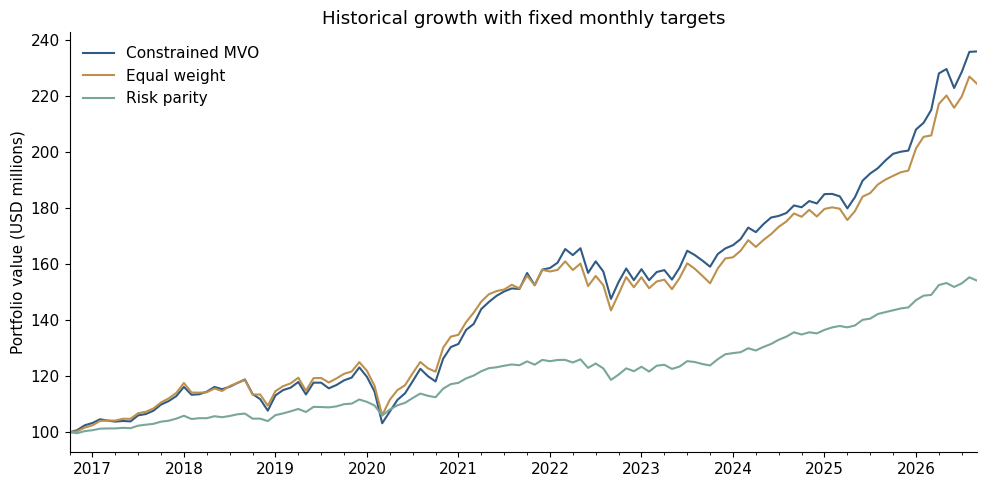

In [14]:
wealth = CAPITAL * (1 + backtest_returns).cumprod()
wealth.loc[evaluation.index[0] - pd.offsets.MonthEnd(1)] = CAPITAL
wealth = wealth.sort_index()
figure, axis = plt.subplots()
(wealth / 1_000_000).plot(ax=axis, color=["#315b83", "#bd904d", "#78a69b"])
axis.set(title="Historical growth with fixed monthly targets", ylabel="Portfolio value (USD millions)", xlabel="")
axis.legend(frameon=False)
figure.tight_layout()
figure.savefig(RESULTS / "backtest_growth.png", dpi=170)
plt.show()

## 8. Check using dollar holdings, not the same return formula

Independently hold dollars in each ETF. At each rebalance, compute the dollars bought or sold, deduct costs from net asset value, invest the remaining dollars and apply each ETF return. The resulting monthly portfolio returns must match the weight-based simulator. We also reconstruct risk contributions directly from covariance between each ETF and portfolio returns.

In [15]:
accounting_checks = []
for name, weights in benchmark_weights.items():
    holdings = np.zeros(len(weights))
    nav = float(CAPITAL)
    independent_returns = []
    for _, observations in evaluation.iterrows():
        initial_nav = nav
        dollars_traded = np.abs(initial_nav * weights - holdings).sum()
        fee = TRADING_COST * dollars_traded
        holdings = (initial_nav - fee) * weights * (1 + observations.to_numpy())
        nav = float(holdings.sum())
        independent_returns.append(nav / initial_nav - 1)
    difference = np.max(abs(np.array(independent_returns) - backtest_returns[name].to_numpy()))
    assert difference < 1e-12
    accounting_checks.append([name, len(independent_returns), difference])
display(pd.DataFrame(accounting_checks, columns=["Portfolio", "Months checked", "Largest return difference"]))

direct_portfolio_returns = training.to_numpy() @ target_weights
direct_variance = np.var(direct_portfolio_returns, ddof=1) * 12
direct_shares = np.array([
    target_weights[i] * np.cov(training.iloc[:, i], direct_portfolio_returns, ddof=1)[0, 1] * 12 / direct_variance
    for i in range(len(ASSETS))
])
assert np.max(abs(direct_shares - allocation["risk_share"].to_numpy())) < 1e-10
assert policy_checks["passes"].all()
assert abs(target_weights.sum() - 1) < 1e-12
print("Dollar accounting, direct risk contributions and policy checks passed.")

,Portfolio,Months checked,Largest return difference
0,Constrained MVO,119,4.440892e-16
1,Equal weight,119,4.440892e-16
2,Risk parity,119,4.440892e-16


Dollar accounting, direct risk contributions and policy checks passed.


## 9. Implemented whole-share positions

`Data/positions.csv` contains the chosen quantities and closing prices **supplied by Kyla for 16 October 2026**. These are reference prices, not independently downloaded execution confirmations. Historical prices ending September determine the target weights; October reference prices determine share quantities. We do not treat October's partial month as a completed monthly return.

$$\text{position value}=\text{shares}\times\text{reference price},\qquad
w_i^{actual}=\frac{\text{position value}_i}{100{,}000{,}000}.$$
Whole shares make actual weights slightly different from targets. VGSH was rounded up to respect its 5% floor; four additional STIP shares reduced residual cash to USD 12.12. The implemented risk estimate below treats residual cash as zero volatility. Actual execution costs are not deducted from these reference-price quantities.

In [16]:
positions = pd.read_csv(DATA / "positions.csv").set_index("ticker")
assert (positions["shares"] >= 0).all() and (positions["shares"] % 1 == 0).all()
value_cents = pd.Series({ticker: int(Decimal(str(row.closing_price_usd)) * 100) * int(row.shares)
                         for ticker, row in positions.iterrows()})
positions["position_value_usd"] = value_cents / 100
positions["actual_weight"] = positions["position_value_usd"] / CAPITAL
positions["target_weight"] = allocation["target_weight"].reindex(positions.index)
positions["difference_percentage_points"] = (positions["actual_weight"] - positions["target_weight"]) * 100
cash_cents = CAPITAL * 100 - int(value_cents.sum())
assert cash_cents >= 0
actual_weights = positions["actual_weight"].reindex(ASSETS, fill_value=0).to_numpy()
assert policy_margins(actual_weights, covariance, ASSETS, POLICY).min() >= -1e-10
actual_volatility = portfolio_volatility(actual_weights, covariance)
assert 0.07 <= actual_volatility <= 0.09
display(positions.style.format({"closing_price_usd": "${:,.2f}", "shares": "{:,.0f}",
    "position_value_usd": "${:,.2f}", "actual_weight": "{:.6%}", "target_weight": "{:.2%}",
    "difference_percentage_points": "{:+.6f}"}))
print(f"Invested: ${value_cents.sum() / 100:,.2f}; cash: ${cash_cents / 100:,.2f}")
print(f"Implemented estimated volatility: {actual_volatility:.6%}")

,closing_price_usd,shares,price_date,position_value_usd,actual_weight,target_weight,difference_percentage_points
ticker,,,,,,,
SPY,$763.25,"34,169",2026-10-16,"$26,079,489.25",26.079489%,26.08%,-0.000511
EEMV,$72.30,"133,610",2026-10-16,"$9,660,003.00",9.660003%,9.66%,+0.000003
DBC,$33.74,"798,756",2026-10-16,"$26,950,027.44",26.950027%,26.95%,+0.000027
VGSH,$57.69,"86,671",2026-10-16,"$5,000,049.99",5.000050%,5.00%,+0.000050
SCHD,$34.35,"95,488",2026-10-16,"$3,280,012.80",3.280013%,3.28%,+0.000013
STIP,$100.58,"288,630",2026-10-16,"$29,030,405.40",29.030405%,29.03%,+0.000405


Invested: $99,999,987.88; cash: $12.12
Implemented estimated volatility: 7.999573%


## 10. Save the tables

The saved CSVs contain ordinary numeric tables. The notebook above is the explanation and computation; there are no extra metadata sidecars or hidden project-code dependencies.

**Interpretation:** the selected allocation satisfies our chosen limits, but its exact weights depend on noisy historical means and policy choices. Its Sharpe advantage over equal weight is modest. Risk parity carries less risk and has a lower current risk estimate, so its historical return is not a risk-matched comparison. The supplementary notebook records sensitivity, earlier trials and uncertainty without selecting new limits from the best historical performance.

In [17]:
output_tables = {
    "allocation.csv": allocation,
    "annual_inputs.csv": annual_inputs,
    "annual_covariance.csv": annual_covariance,
    "correlations.csv": training.corr(),
    "monthly_etf_returns.csv": returns,
    "monthly_risk_free.csv": risk_free_table,
    "benchmark_comparison.csv": benchmark_comparison,
    "benchmark_volatility.csv": benchmark_volatility.to_frame(),
    "backtest_summary.csv": backtest_summary,
    "monthly_backtest_returns.csv": backtest_returns,
    "monthly_wealth.csv": wealth,
    "positions.csv": positions,
    "policy_checks.csv": policy_checks,
    "solver_diagnostics.csv": solver_diagnostics,
}
for filename, table in output_tables.items():
    table.to_csv(RESULTS / filename)
print("Saved the calculated tables in Results/.")

Saved the calculated tables in Results/.
